# Ориентация текстовых боксов Avito

Главная метрика равна $1-\mathrm{Brier}$, где $\mathrm{Brier}=\frac1N\sum_i(p_i-y_i)^2$.

Перед выполнением: `%pip install -r requirements.txt`.

Обычный запуск создаёт 10 000 базовых синтетических изображений.

Для быстрой проверки до запуска ядра можно задать `AVITO_N_BASE_SAMPLES=600`.

## 1. Настройка

In [10]:
from pathlib import Path
from collections import Counter
from functools import partial
import io, os, pickle, random, time, warnings

import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("module://matplotlib_inline.backend_inline", force=True)
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw, ImageEnhance, ImageFilter, ImageFont
from skimage.feature import hog
from sklearn.base import clone
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, brier_score_loss, roc_auc_score
from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.svm import LinearSVC
try:
    from sklearn.frozen import FrozenEstimator
except ImportError:
    FrozenEstimator = None
import joblib

RANDOM_SEED = 42
N_BASE_SAMPLES = int(os.environ.get('AVITO_N_BASE_SAMPLES', '10000'))
VAL_FRACTION = 0.20
CAL_FRACTION = 0.20                                                 
HOG_SIZE = (128, 32)                                         
ARTIFACT_DIR = Path('artifacts')
ARTIFACT_DIR.mkdir(exist_ok=True)
rng = np.random.default_rng(RANDOM_SEED)
random.seed(RANDOM_SEED)
print('N_BASE_SAMPLES:', N_BASE_SAMPLES)

N_BASE_SAMPLES: 10000


Фиксируем seed и размер выборки. 

Все результаты сохраним в `artifacts/`.

## 2. Что лежит в test

In [11]:
ROOT = Path.cwd()
submissions = sorted(ROOT.rglob('sample_submission.csv'), key=lambda p: len(p.parts))
assert len(submissions) == 1, f'Ожидался один sample_submission.csv; найдено {submissions}'
sample_path = submissions[0]
sample = pd.read_csv(sample_path, dtype={'image_id': str})
assert list(sample.columns) == ['image_id', 'p_180']
assert sample.image_id.is_unique

extensions = {'.png', '.jpg', '.jpeg', '.webp', '.bmp', '.tif', '.tiff'}
image_dirs = []
for directory in ROOT.rglob('*'):
    if directory.is_dir() and ARTIFACT_DIR not in directory.parents and directory != ARTIFACT_DIR:
        files = [p for p in directory.iterdir() if p.is_file() and p.suffix.lower() in extensions]
        if files:
            image_dirs.append((directory, files))
image_dir, image_files = max(image_dirs, key=lambda item: len(item[1]))
assert len(image_files) == 20000, f'Ожидалось 20000 изображений, найдено {len(image_files)}'
by_stem = {p.stem: p for p in image_files}
assert len(by_stem) == len(image_files), 'Дублирующиеся stem у файлов'
assert set(sample.image_id) == set(by_stem), 'image_id в sample и файлах не совпадают'
test_paths = [by_stem[x] for x in sample.image_id]                              
print('Каталог:', image_dir, '| форматы:', Counter(p.suffix.lower() for p in image_files))
print('Изображений:', len(test_paths), '| строк sample:', len(sample))
display(sample.head())

Каталог: /home/nick-pc/Programming/avito-task/test/images | форматы: Counter({'.png': 20000})
Изображений: 20000 | строк sample: 20000


,image_id,p_180
0,test_00000,0.5
1,test_00001,0.5
2,test_00002,0.5
3,test_00003,0.5
4,test_00004,0.5


Идентификаторы берём из sample submission.

In [12]:
records = []
for path in test_paths:
    with Image.open(path) as im:
        a = np.asarray(im.convert('L').resize((64, 32)), dtype=np.float32)
        records.append((path.stem, im.width, im.height, im.mode,
                        float(a.mean()), float(a.std()),
                        float(np.percentile(a, 5)), float(np.percentile(a, 95)),
                        float((a < 128).mean())))
eda = pd.DataFrame(records, columns=['image_id','width','height','mode','brightness',
                                     'contrast','p05','p95','dark_fraction'])


,width,height,aspect_ratio,brightness,contrast,dark_fraction
0.00,25.00,10.0,0.720930,5.680176,1.249815,0.000000
0.01,40.00,12.0,1.761886,34.325239,8.888179,0.000000
0.05,61.00,16.0,2.319909,54.466113,16.070616,0.000000
0.25,129.00,27.0,3.503241,99.502563,30.217909,0.130859
0.50,238.00,42.0,4.894899,142.162354,43.066715,0.355469
0.75,479.25,76.0,7.518636,184.270752,56.769922,0.725586
0.95,1047.00,195.0,14.447785,219.765649,76.063582,0.986328
0.99,1406.00,289.0,22.609812,235.928237,89.540071,1.000000
1.00,1599.00,492.0,49.666667,252.252441,107.564079,1.000000


width  height
92     20        13
68     19        12
56     16        10
86     18         9
76     24         9
88     27         9
50     14         9
41     13         9
       14         9
50     13         9
dtype: int64

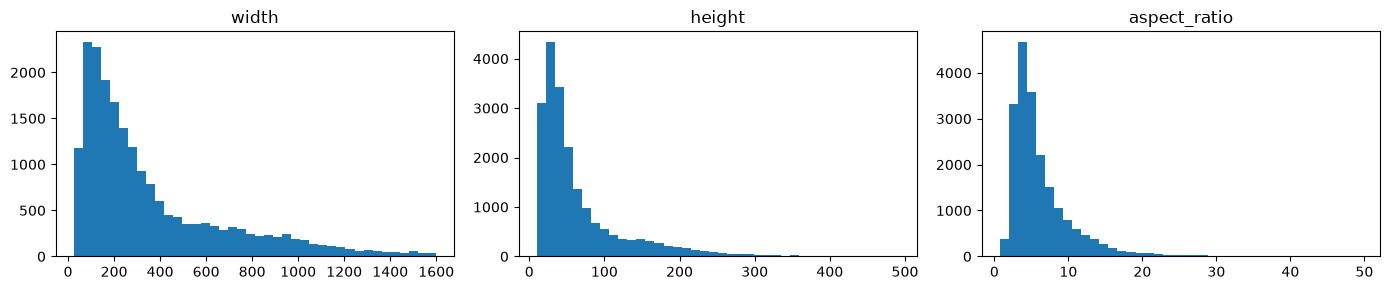

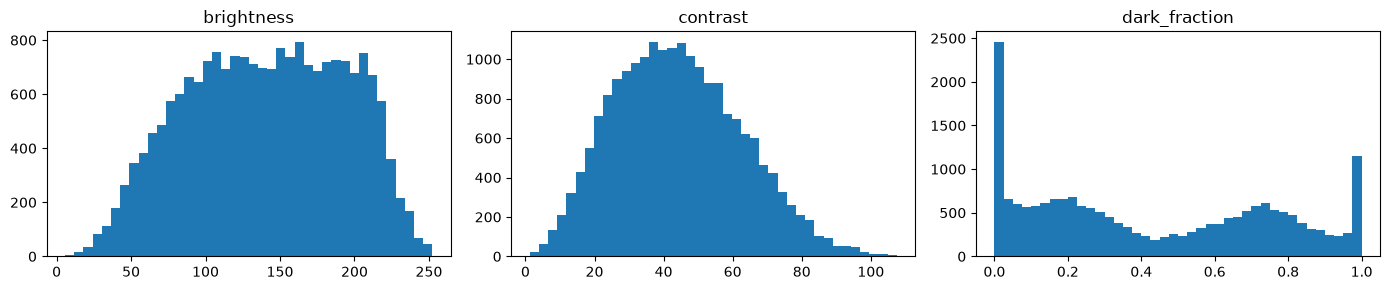

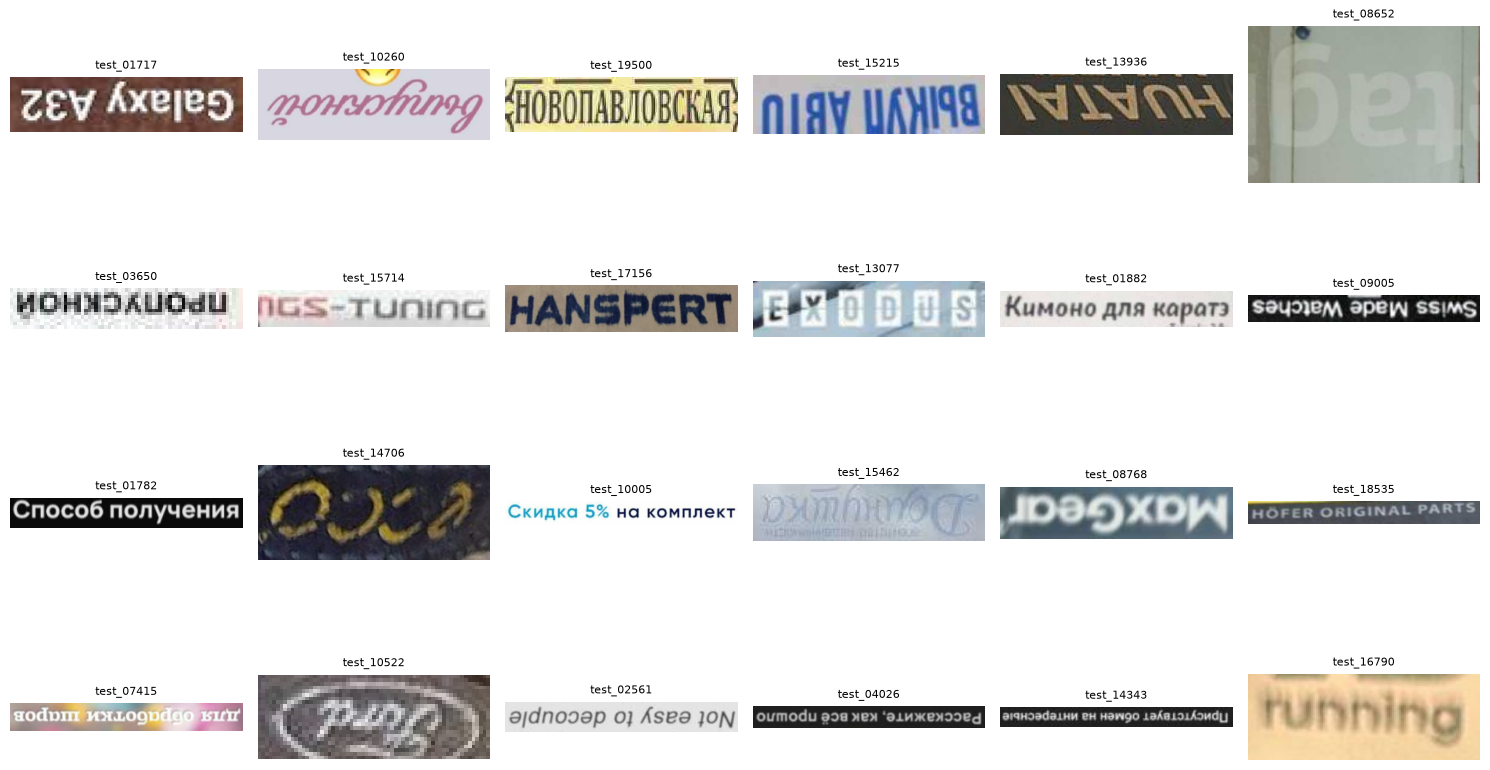

In [13]:
eda['aspect_ratio'] = eda.width / eda.height
eda.to_csv(ARTIFACT_DIR / 'test_eda.csv', index=False)
display(eda[['width','height','aspect_ratio','brightness','contrast','dark_fraction']].quantile([0,.01,.05,.25,.5,.75,.95,.99,1]))
display(eda.groupby(['width','height']).size().sort_values(ascending=False).head(10))
fig, axs = plt.subplots(1, 3, figsize=(14, 3))
for ax, col in zip(axs, ['width','height','aspect_ratio']):
    ax.hist(eda[col], bins=40); ax.set_title(col)
plt.tight_layout(); plt.show()
fig, axs = plt.subplots(1, 3, figsize=(14, 3))
for ax, col in zip(axs, ['brightness','contrast','dark_fraction']):
    ax.hist(eda[col], bins=40); ax.set_title(col)
plt.tight_layout(); plt.show()

chosen = rng.choice(len(test_paths), size=24, replace=False)
fig, axs = plt.subplots(4, 6, figsize=(15, 9))
for ax, i in zip(axs.flat, chosen):
    ax.imshow(Image.open(test_paths[i])); ax.set_title(test_paths[i].stem, fontsize=8); ax.axis('off')
plt.tight_layout(); plt.show()

Смотрим на размеры, цвет, яркость и случайные примеры. 

Настраиваем синтетику.

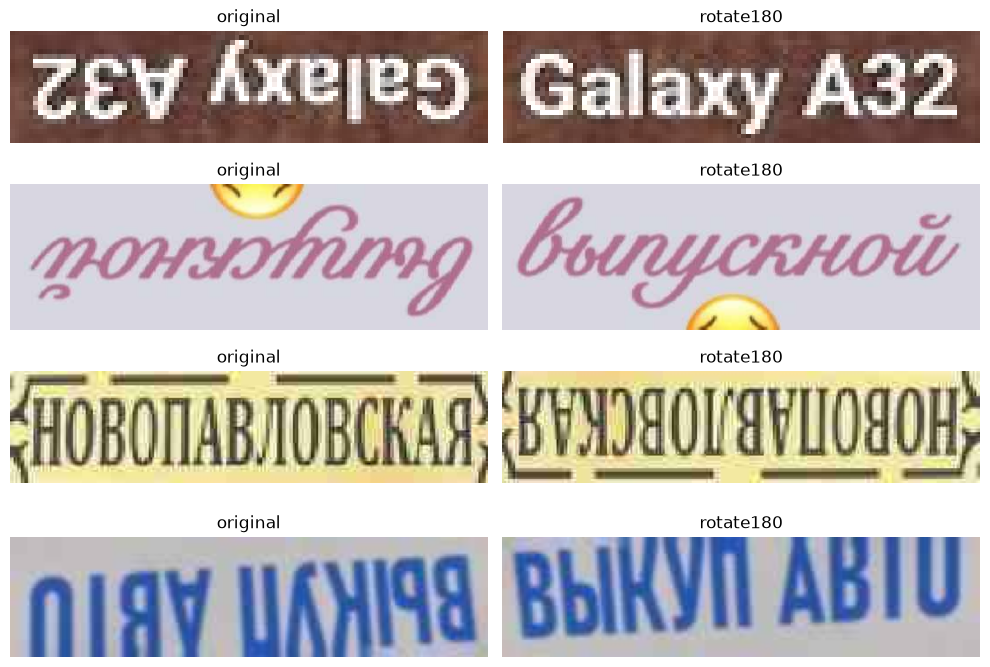

In [14]:
def rotate_180(image: Image.Image) -> Image.Image:
    return image.transpose(Image.Transpose.ROTATE_180)

fig, axs = plt.subplots(4, 2, figsize=(10, 7))
for row, i in enumerate(chosen[:4]):
    with Image.open(test_paths[i]) as im:
        axs[row, 0].imshow(im); axs[row, 1].imshow(rotate_180(im))
    axs[row, 0].set_title('original'); axs[row, 1].set_title('rotate180')
for ax in axs.flat: ax.axis('off')
plt.tight_layout(); plt.show()

Поворот $R_{180}$ меняет метку пары. В идеале $p(R_{180}x)=1-p(x)$, в будущем проверим и у моделей.

## 3. Синтетические строки

Используем системные шрифты и скачиваем PT Sans, PT Serif и PT Sans Narrow с кириллицей. Файлы сохраняются в `artifacts/fonts/`.


In [15]:
from urllib.request import urlopen
from hashlib import sha256

font_dir = ARTIFACT_DIR / 'fonts'
font_dir.mkdir(exist_ok=True)
font_specs = [
    ('ptsans', 'PT_Sans-Web-Regular.ttf', '9cc831490532009bae2b3ce0d39c62adfc889060beb421593bfd9d2396d0f10a'),
    ('ptsans', 'PT_Sans-Web-Bold.ttf', '3128bd5ecf01816e59a23d54c57a7a6b14615b07db53ff277c77376010265b05'),
    ('ptserif', 'PT_Serif-Web-Regular.ttf', 'a4951fade06ff8f09b7673aa81ffb65a8cd409e24d3289a6dc670bc4dda2557a'),
    ('ptsansnarrow', 'PT_Sans-Narrow-Web-Regular.ttf', '4102edda03059163771869d258df54ac8563c408fa6e9ef75b2ddc85eabea6f4'),
]

def supports_cyrillic(path):
    try:
        from fontTools.ttLib import TTFont
        font = TTFont(str(path), lazy=True)
        cmap = font.getBestCmap() or {}
        font.close()
        return all(ord(ch) in cmap for ch in 'ПриветHello123₽№')
    except Exception:
        return False

downloaded_fonts = []
for family, name, expected_hash in font_specs:
    path = font_dir / name
    valid = path.exists() and sha256(path.read_bytes()).hexdigest() == expected_hash
    if not valid:
        url = f'https://raw.githubusercontent.com/google/fonts/main/ofl/{family}/{name}'
        try:
            data = urlopen(url, timeout=20).read()
        except OSError as exc:
            print(f'Не удалось скачать {name}: {exc}')
            continue
        if sha256(data).hexdigest() != expected_hash:
            raise ValueError(f'Изменилась версия файла {name}')
        path.write_bytes(data)
    if not supports_cyrillic(path):
        raise ValueError(f'В шрифте {name} нет нужных символов')
    downloaded_fonts.append(path)
    license_path = font_dir / f'{family}_OFL.txt'
    if not license_path.exists():
        license_url = f'https://raw.githubusercontent.com/google/fonts/main/ofl/{family}/OFL.txt'
        try:
            license_path.write_bytes(urlopen(license_url, timeout=20).read())
        except OSError as exc:
            print(f'Не удалось скачать лицензию {family}: {exc}')

font_roots = [Path('/usr/share/fonts'), Path('/usr/local/share/fonts'), Path.home()/'.local/share/fonts', Path('C:/Windows/Fonts')]
font_paths = sorted({p for root in font_roots if root.exists() for ext in ('*.ttf', '*.otf') for p in root.rglob(ext)})
preferred = [p for p in font_paths if any(s in p.name.lower() for s in
             ('dejavu', 'liberation', 'noto', 'opensans', 'open-sans', 'ubuntu', 'lato', 'arial')) and supports_cyrillic(p)]
fonts = sorted(set((preferred if preferred else [p for p in font_paths if supports_cyrillic(p)]) + downloaded_fonts))
assert fonts, 'Не найдено шрифтов с кириллицей'
font_signature = '|'.join(f'{p.name}:{sha256(p.read_bytes()).hexdigest()}' for p in downloaded_fonts)
FONT_SET_VERSION = sha256(font_signature.encode()).hexdigest()[:10]
print('Скачано PT-шрифтов:', len(downloaded_fonts))
print('Всего шрифтов в генераторе:', len(fonts))
print('Новые шрифты:', [p.name for p in downloaded_fonts])

ru = 'привет доставка квартира скидка новый телефон автомобиль цена продажа сегодня гарантия Москва Санкт-Петербург отличный'.split()
en = 'Hello delivery apartment discount new phone car price sale today warranty original limited edition'.split()
brands = ['iPhone 15 Pro 256GB','Samsung Galaxy S24','RTX 4060 8GB','MacBook Air M2','Toyota Camry 2018']
def random_text(rng):
    kind = rng.choice(['ru','en','mix','number','price','percent','date','phone','brand','short','long'])
    if kind == 'ru': return ' '.join(rng.choice(ru, size=int(rng.integers(1,5))))
    if kind == 'en': return ' '.join(rng.choice(en, size=int(rng.integers(1,5))))
    if kind == 'mix': return f'{rng.choice(ru)} {int(rng.integers(1,999))} {rng.choice(en)}'
    if kind == 'number': return str(int(rng.integers(10,10000000)))
    if kind == 'price': return f'{int(rng.integers(100,99999)):,} ₽'.replace(',', ' ')
    if kind == 'percent': return f'{int(rng.integers(1,100))}% скидка'
    if kind == 'date': return f'{int(rng.integers(1,29)):02d}.{int(rng.integers(1,13)):02d}.{int(rng.integers(2020,2030))}'
    if kind == 'phone': return f'+7 ({int(rng.integers(900,999))}) {int(rng.integers(100,999))}-{int(rng.integers(10,99))}-{int(rng.integers(10,99))}'
    if kind == 'brand': return str(rng.choice(brands))
    if kind == 'short': return str(rng.choice(['Да','Нет','OK','100','А1','5G','Wi-Fi','№ 3']))
    return ' '.join(rng.choice(ru if rng.random()<.5 else en, size=int(rng.integers(5,10))))

Скачано PT-шрифтов: 4
Всего шрифтов в генераторе: 12
Новые шрифты: ['PT_Sans-Web-Regular.ttf', 'PT_Sans-Web-Bold.ttf', 'PT_Serif-Web-Regular.ttf', 'PT_Sans-Narrow-Web-Regular.ttf']


Меняем размер, фон, положение текста и умеренно искажаем изображение. Геометрию берём из test без его меток.

In [16]:
AUG = dict(blur_prob=.25, noise_prob=.30, jpeg_prob=.25, affine_prob=.30,
           crop_prob=.15, padding_prob=.15, brightness_range=(.75,1.25),
           contrast_range=(.8,1.25))
geometry = eda[['width','height']].to_numpy()
def choose_geometry(rng):
                                                                         
    w, h = geometry[int(rng.integers(len(geometry)))]
    return int(w), int(h)

def render_text(text, font_path, width, height, rng, aug=AUG):
    bg = int(rng.integers(200,256)) if rng.random()<.85 else int(rng.integers(0,70))
    fg = int(rng.integers(0,115)) if bg>128 else int(rng.integers(160,256))
    im = Image.new('L', (width,height), bg)
    draw = ImageDraw.Draw(im)
    margin = max(1, int(height*rng.uniform(.04,.20)))
                                                                                         
    size = max(6, int(height*rng.uniform(.55,1.05)))
    for candidate in range(size, 5, -1):
        font = ImageFont.truetype(str(font_path), candidate)
        box = draw.textbbox((0,0), text, font=font)
        tw, th = box[2]-box[0], box[3]-box[1]
        if tw <= max(1,width-2*margin) and th <= max(1,height-2*margin): break
                                                                                                
    x = int(rng.uniform(-max(0,tw-width)*.5, max(0,width-tw))) if tw != width else 0
    y = int(rng.uniform(0,max(0,height-th))) - box[1]
    draw.text((x,y), text, fill=fg, font=font)
    if rng.random()<aug['affine_prob']:
        shift = rng.uniform(-.04,.04)*height
        shear = rng.uniform(-.06,.06)
        im = im.transform(im.size, Image.Transform.AFFINE, (1,shear,-shift,0,1,0),
                          resample=Image.Resampling.BICUBIC, fillcolor=bg)
    if rng.random()<aug['crop_prob'] and width>12 and height>8:
        cut = int(rng.integers(1,max(2,int(min(width,height)*.07))))
        im = im.crop((cut,0,width,height)).resize((width,height),Image.Resampling.BILINEAR)
    if rng.random()<aug['padding_prob']:
        pad = max(1,int(height*rng.uniform(.01,.08)))
        tmp = Image.new('L',(width+2*pad,height+2*pad),bg); tmp.paste(im,(pad,pad))
        im = tmp.resize((width,height),Image.Resampling.BILINEAR)
    im = ImageEnhance.Brightness(im).enhance(float(rng.uniform(*aug['brightness_range'])))
    im = ImageEnhance.Contrast(im).enhance(float(rng.uniform(*aug['contrast_range'])))
    if rng.random()<aug['blur_prob']: im=im.filter(ImageFilter.GaussianBlur(float(rng.uniform(.2,1.0))))
    if rng.random()<aug['noise_prob']:
        arr=np.asarray(im).astype(np.float32)+rng.normal(0,float(rng.uniform(2,12)),im.size[::-1])
        im=Image.fromarray(np.uint8(np.clip(arr,0,255)))
    if rng.random()<aug['jpeg_prob']:
        buffer=io.BytesIO(); im.save(buffer,format='JPEG',quality=int(rng.integers(45,95)))
        buffer.seek(0); im=Image.open(buffer).convert('L')
    return im

## 4. Пары и разделение данных

Каждая исходная строка даёт нормальное изображение с `y=0` и повёрнутое с `y=1`. Делим исходные строки до создания пар. Так одна строка не попадёт одновременно в обучение и проверку.

In [17]:
                                                                                                   
base_dir = ARTIFACT_DIR/f'synthetic_base_{FONT_SET_VERSION}'; base_dir.mkdir(exist_ok=True)
manifest_path = ARTIFACT_DIR/f'synthetic_manifest_{N_BASE_SAMPLES}_{RANDOM_SEED}_{FONT_SET_VERSION}.csv'
if manifest_path.exists():
    manifest = pd.read_csv(manifest_path)
else:
    rows=[]
    for group_id in range(N_BASE_SAMPLES):
        text = random_text(rng); font_path = fonts[int(rng.integers(len(fonts)))]
        width,height=choose_geometry(rng)
        im=render_text(text,font_path,width,height,rng)
        path=base_dir/f'{RANDOM_SEED}_{group_id:06d}.png'; im.save(path)
        rows.append((group_id,str(path),text,font_path.name,width,height))
    manifest=pd.DataFrame(rows,columns=['group_id','path','text','font','width','height'])
    manifest.to_csv(manifest_path,index=False)
assert len(manifest)==N_BASE_SAMPLES and all(Path(p).exists() for p in manifest.path)

groups=manifest.group_id.to_numpy()
traincal_idx,val_idx=next(GroupShuffleSplit(n_splits=1,test_size=VAL_FRACTION,random_state=RANDOM_SEED).split(groups,groups=groups))
train_idx,cal_idx=next(GroupShuffleSplit(n_splits=1,test_size=CAL_FRACTION,random_state=RANDOM_SEED+1).split(traincal_idx,groups=groups[traincal_idx]))
train_idx,cal_idx=traincal_idx[train_idx],traincal_idx[cal_idx]
assert not (set(groups[train_idx]) & set(groups[val_idx]) | set(groups[cal_idx]) & set(groups[val_idx]) | set(groups[train_idx]) & set(groups[cal_idx]))

def paired_index(base_indices):
    ids=np.repeat(base_indices,2)
    labels=np.tile(np.array([0,1],dtype=np.int8),len(base_indices))
    return ids,labels
tr_ids,y_train=paired_index(train_idx)
ca_ids,y_cal=paired_index(cal_idx)
va_ids,y_val=paired_index(val_idx)
print('base train/cal/val:',len(train_idx),len(cal_idx),len(val_idx))
print('paired observations:',len(y_train),len(y_cal),len(y_val))
assert np.mean(y_train)==np.mean(y_cal)==np.mean(y_val)==.5

base train/cal/val: 6400 1600 2000
paired observations: 12800 3200 4000


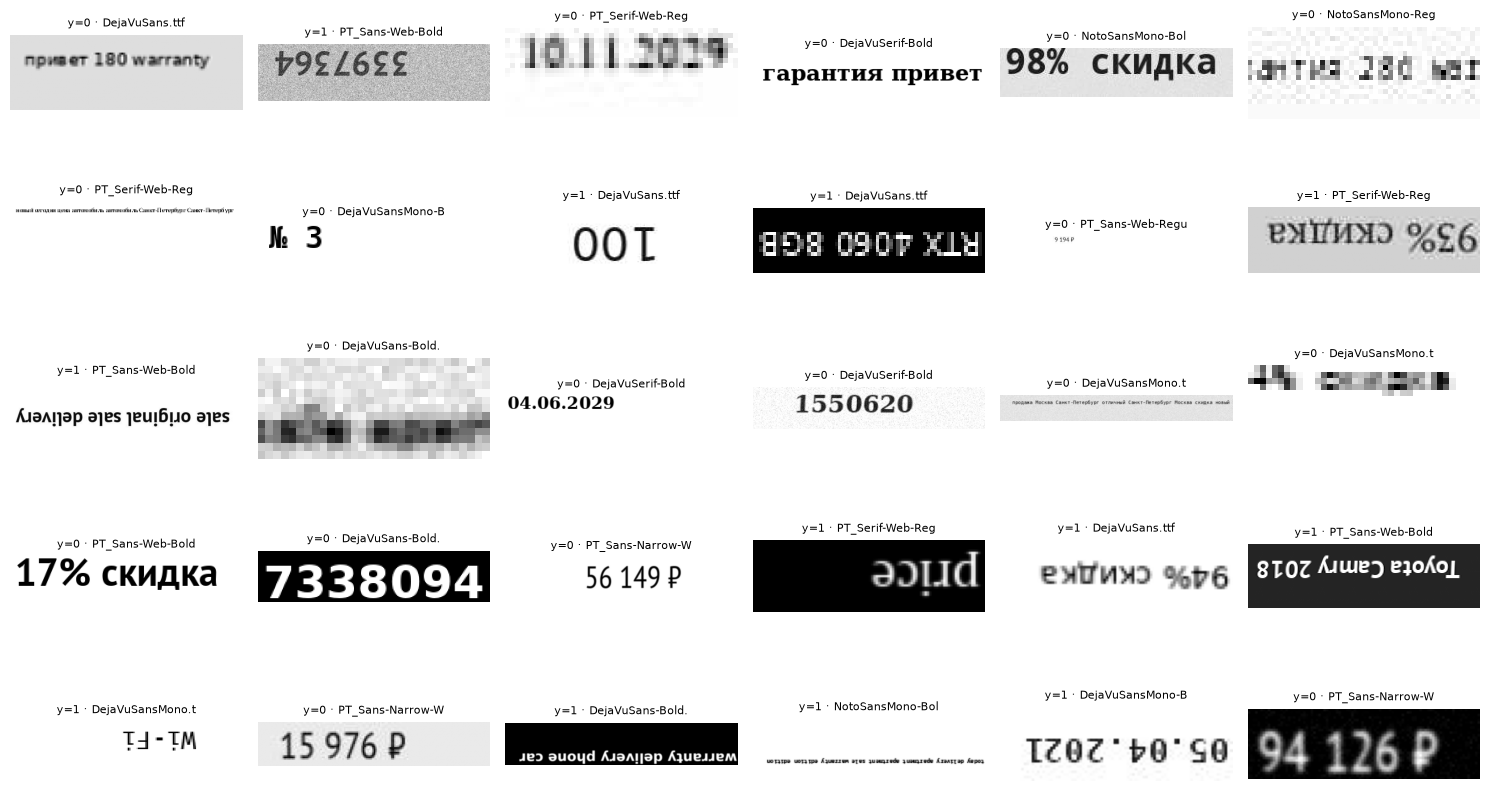

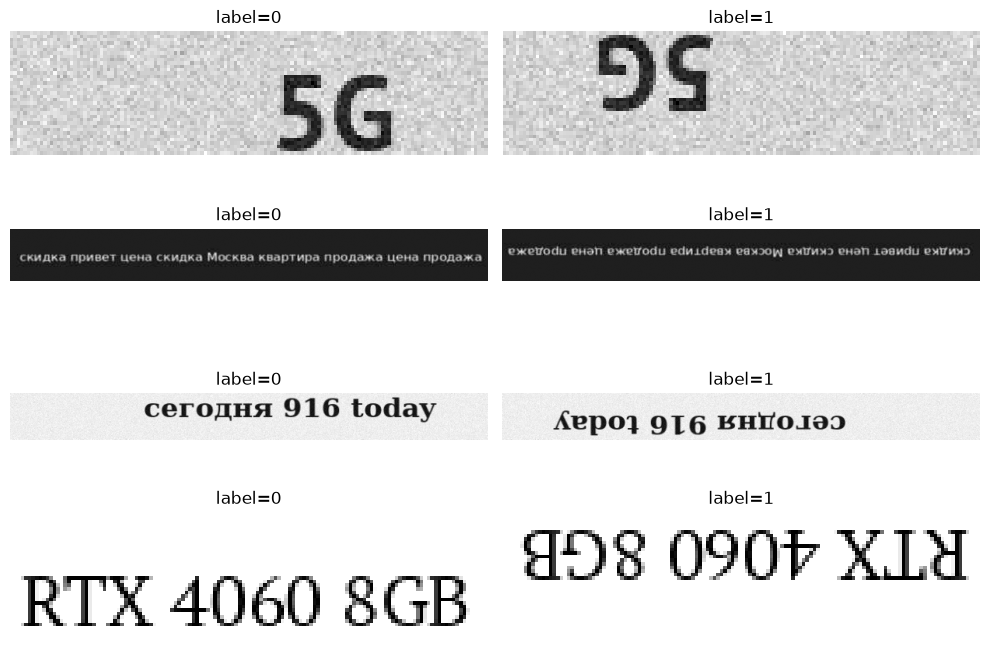

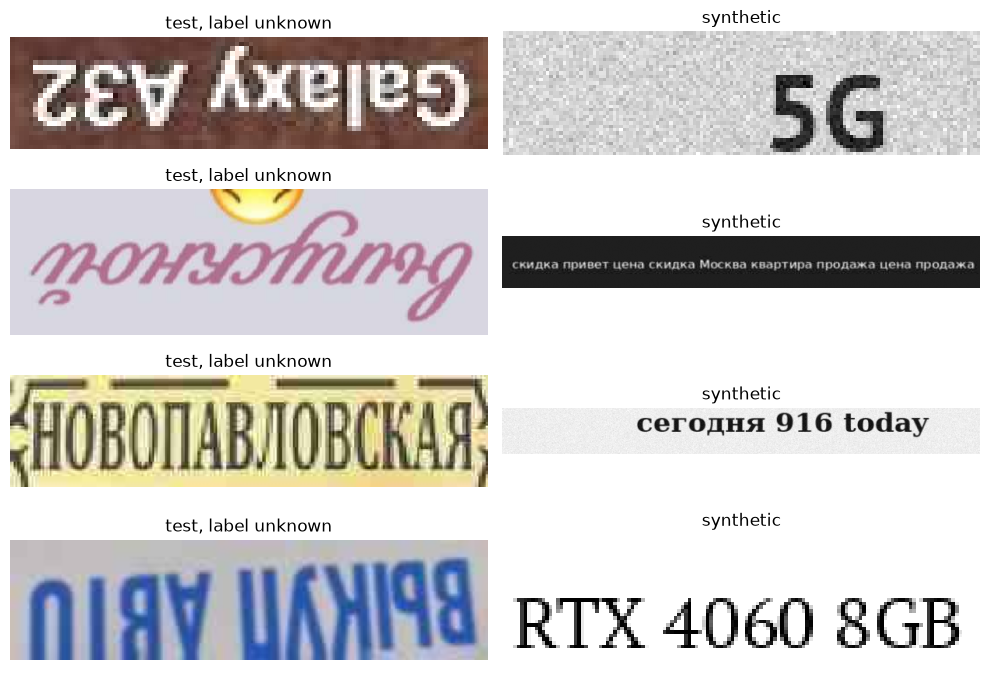

In [18]:
def get_synthetic(base_idx, label):
    with Image.open(manifest.iloc[int(base_idx)].path) as source:
        im=source.copy()
    return rotate_180(im) if label else im

pick=rng.choice(len(va_ids),size=min(30,len(va_ids)),replace=False)
fig,axs=plt.subplots(5,6,figsize=(15,9))
for ax,k in zip(axs.flat,pick):
    ax.imshow(get_synthetic(va_ids[k],y_val[k]),cmap='gray')
    ax.set_title(f'y={y_val[k]} · {manifest.iloc[va_ids[k]].font[:16]}',fontsize=8); ax.axis('off')
plt.tight_layout(); plt.show()
fig,axs=plt.subplots(4,2,figsize=(10,7))
for row,i in enumerate(val_idx[:4]):
    for col in (0,1):
        axs[row,col].imshow(get_synthetic(i,col),cmap='gray'); axs[row,col].set_title(f'label={col}'); axs[row,col].axis('off')
plt.tight_layout(); plt.show()
fig,axs=plt.subplots(4,2,figsize=(10,7))
for row,i in enumerate(val_idx[:4]):
    axs[row,0].imshow(Image.open(test_paths[chosen[row]]),cmap='gray'); axs[row,0].set_title('test, label unknown')
    axs[row,1].imshow(get_synthetic(i,0),cmap='gray'); axs[row,1].set_title('synthetic')
for ax in axs.flat: ax.axis('off')
plt.tight_layout(); plt.show()

На сетке видны читаемость, разнообразие и различия с test. Сходство распределений не предполагаем.

## 5. Первый ориентир

У сбалансированной пары постоянное `p=0.5` даёт Brier `0.25` и score `0.75`. Это точка отсчёта.

In [19]:
results=[]
def metrics(name,y,p,feature_dim,train_s,infer_s,model_bytes=0,preprocess_s=np.nan):
    p=np.asarray(p,dtype=float)
    row=dict(model=name,features=feature_dim,score=1-brier_score_loss(y,p),
             brier=brier_score_loss(y,p),accuracy=accuracy_score(y,p>=.5),
             auc=roc_auc_score(y,p),training_s=train_s,
             inference_ms=1000*infer_s/len(p),images_sec=len(p)/infer_s if infer_s else np.inf,
             preprocessing_ms=1000*preprocess_s/len(p) if np.isfinite(preprocess_s) else np.nan,
             model_size_mb=model_bytes/1024**2)
    results.append(row)
    return pd.Series(row)

t0=time.perf_counter(); constant=np.full(len(y_val),.5); t_const=time.perf_counter()-t0
display(metrics('constant 0.5',y_val,constant,0,0,t_const,0,0))
print('Balanced y: Brier = .25; accuracy uses p>=.5 and is .5. AUC = .5.')

model                  constant 0.5
features                          0
score                          0.75
brier                          0.25
accuracy                        0.5
auc                             0.5
training_s                        0
inference_ms               0.000012
images_sec          84584480.175669
preprocessing_ms                0.0
model_size_mb                   0.0
dtype: object

Balanced y: Brier = .25; accuracy uses p>=.5 and is .5. AUC = .5.


## 6. Простые признаки

Проверяем яркость, массу штрихов, горизонтальные профили и градиенты. Вероятность выдаёт Logistic Regression.

In [20]:
def gray_array(im,size=HOG_SIZE):
    return np.asarray(im.convert('L').resize(size,Image.Resampling.BILINEAR),dtype=np.float32)/255

def handcrafted(im):
    a=gray_array(im); ink=np.abs(a-np.median(np.r_[a[0],a[-1],a[:,0],a[:,-1]]))
    h,w=a.shape; yy,xx=np.mgrid[:h,:w]; mass=ink.sum()+1e-8
    hp=np.array_split(ink.mean(axis=1),4); vp=np.array_split(ink.mean(axis=0),4)
    gy,gx=np.gradient(a)
    return np.array([a.mean(),a.std(),np.percentile(a,10),np.percentile(a,90),
                     (ink*yy).sum()/mass/h,(ink*xx).sum()/mass/w,
                     ink[:h//2].mean(),ink[h//2:].mean(),
                     *[v.mean() for v in hp], *[v.mean() for v in vp],
                     np.abs(gx).mean(),np.abs(gy).mean()],dtype=np.float32)

def extract_synthetic(ids,labels,feature_fn):
    start=time.perf_counter()
    x=np.stack([feature_fn(get_synthetic(i,y)) for i,y in zip(ids,labels)])
    return x,time.perf_counter()-start

Xtr_hand,t_tr_hand=extract_synthetic(tr_ids,y_train,handcrafted)
Xca_hand,t_ca_hand=extract_synthetic(ca_ids,y_cal,handcrafted)
Xva_hand,t_va_hand=extract_synthetic(va_ids,y_val,handcrafted)
hand_model=make_pipeline(StandardScaler(),LogisticRegression(max_iter=1000,random_state=RANDOM_SEED))
t0=time.perf_counter(); hand_model.fit(Xtr_hand,y_train); fit_hand=time.perf_counter()-t0
t0=time.perf_counter(); p_hand=hand_model.predict_proba(Xva_hand)[:,1]; predict_hand=time.perf_counter()-t0
display(metrics('handcrafted LR',y_val,p_hand,Xtr_hand.shape[1],fit_hand,
                t_va_hand+predict_hand,len(pickle.dumps(hand_model)),t_va_hand))

model               handcrafted LR
features                        18
score                     0.754473
brier                     0.245527
accuracy                    0.5625
auc                       0.580173
training_s                0.011662
inference_ms               0.71111
images_sec             1406.251463
preprocessing_ms          0.710959
model_size_mb             0.001543
dtype: object

## 7. HOG

HOG описывает расположение локальных контуров. Пробуем три компактных варианта и сравниваем Brier вместе со временем.

In [21]:
def hog_features(im,pixels_per_cell=(8,8),orientations=9):
    a=gray_array(im)
    return hog(a,orientations=orientations,pixels_per_cell=pixels_per_cell,
               cells_per_block=(2,2),block_norm='L2-Hys',feature_vector=True).astype(np.float32)

hog_configs=[('HOG 8x8 / 9', (8,8),9),('HOG 8x8 / 6',(8,8),6),('HOG 12x8 / 9',(8,12),9)]
hog_runs=[]
for name,cell,orient in hog_configs:
    fn=partial(hog_features,pixels_per_cell=cell,orientations=orient)
    Xt,t_xtr=extract_synthetic(tr_ids,y_train,fn)
    Xv,t_xva=extract_synthetic(va_ids,y_val,fn)
    model=make_pipeline(StandardScaler(),LogisticRegression(max_iter=600,random_state=RANDOM_SEED))
    t0=time.perf_counter(); model.fit(Xt,y_train); fit_s=time.perf_counter()-t0
    t0=time.perf_counter(); p=model.predict_proba(Xv)[:,1]; pred_s=time.perf_counter()-t0
    row=metrics(name+' LR',y_val,p,Xt.shape[1],fit_s,t_xva+pred_s,
                len(pickle.dumps(model)),t_xva)
    hog_runs.append(dict(name=name,cell=cell,orient=orient,model=model,p=p,row=row,fn=fn))
    display(row[['model','features','score','brier','accuracy','auc','training_s','inference_ms']])
best_hog=max(hog_runs,key=lambda d:d['row']['score'])
Xtr_hog,t_hog_train=extract_synthetic(tr_ids,y_train,best_hog['fn'])
Xca_hog,t_hog_cal=extract_synthetic(ca_ids,y_cal,best_hog['fn'])
Xva_hog,t_hog_val=extract_synthetic(va_ids,y_val,best_hog['fn'])
print('Лучший HOG config:',best_hog['name'])

model           HOG 8x8 / 9 LR
features                  1620
score                 0.773529
brier                 0.226471
accuracy                0.6425
auc                   0.710295
training_s            8.725333
inference_ms          1.005859
dtype: object

model           HOG 8x8 / 6 LR
features                  1080
score                 0.778107
brier                 0.221893
accuracy               0.63975
auc                   0.705188
training_s             6.30103
inference_ms          0.965867
dtype: object

model           HOG 12x8 / 9 LR
features                    972
score                  0.777871
brier                  0.222129
accuracy                0.64075
auc                    0.702837
training_s             7.091617
inference_ms           0.835181
dtype: object

Лучший HOG config: HOG 8x8 / 6


## 8. Linear SVM

Выход SVM сам по себе не вероятность. Настраиваем sigmoid на отдельной calibration части.

In [22]:
svm=make_pipeline(StandardScaler(),LinearSVC(random_state=RANDOM_SEED,dual=False,max_iter=3000))
t0=time.perf_counter(); svm.fit(Xtr_hog,y_train); svm_fit=time.perf_counter()-t0
raw_scores=svm.decision_function(Xva_hog)
                                                                                         
                                                                                         
from scipy.special import expit
p_naive=expit(raw_scores)
print('Некалиброванная expit(decision_function), Brier только для иллюстрации:',brier_score_loss(y_val,p_naive))
t0=time.perf_counter()
svm_cal=(CalibratedClassifierCV(estimator=FrozenEstimator(svm),method='sigmoid')
         if FrozenEstimator else CalibratedClassifierCV(estimator=svm,method='sigmoid',cv='prefit'))
                                                                         
with warnings.catch_warnings():
    warnings.simplefilter('ignore',FutureWarning)
    svm_cal.fit(Xca_hog,y_cal)
cal_fit=time.perf_counter()-t0
t0=time.perf_counter(); p_svm=svm_cal.predict_proba(Xva_hog)[:,1]; svm_pred=time.perf_counter()-t0
display(metrics('HOG SVM sigmoid',y_val,p_svm,Xtr_hog.shape[1],svm_fit+cal_fit,
                t_hog_val+svm_pred,len(pickle.dumps(svm_cal)),t_hog_val))

Некалиброванная expit(decision_function), Brier только для иллюстрации: 0.22009032504491638


model               HOG SVM sigmoid
features                       1080
score                      0.782646
brier                      0.217354
accuracy                     0.6415
auc                        0.705619
training_s                 8.163601
inference_ms               0.965432
images_sec              1035.806119
preprocessing_ms           0.952743
model_size_mb              0.034288
dtype: object

## 9. Качество вероятностей

Сравниваем исходные вероятности, sigmoid и isotonic. На графике хорошая калибровка лежит около диагонали.

model       HOG LR sigmoid
score             0.782667
brier             0.217333
accuracy           0.63975
auc               0.705188
dtype: object

model       HOG LR isotonic
score              0.783449
brier              0.216551
accuracy             0.6405
auc                0.703326
dtype: object

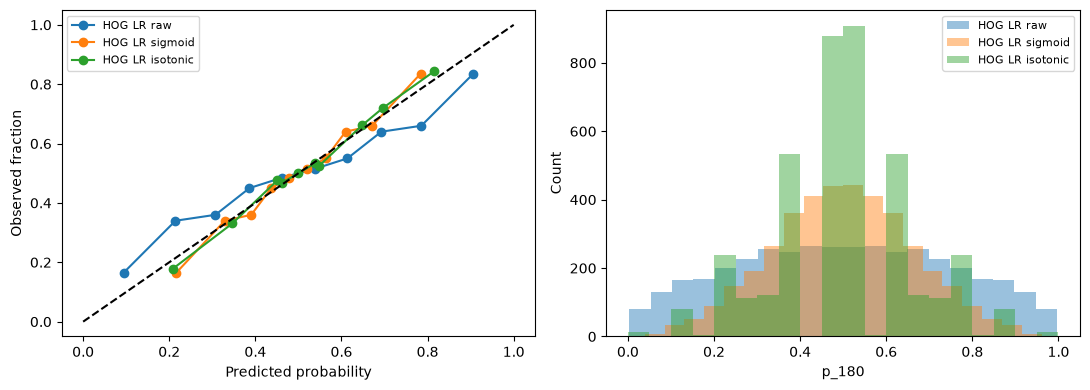

In [23]:
                                                              
base_lr=best_hog['model']
cal_models={'HOG LR raw':base_lr}
for method in ('sigmoid','isotonic'):
    m=(CalibratedClassifierCV(estimator=FrozenEstimator(base_lr),method=method)
       if FrozenEstimator else CalibratedClassifierCV(estimator=base_lr,method=method,cv='prefit'))
    t0=time.perf_counter()
    with warnings.catch_warnings():
        warnings.simplefilter('ignore',FutureWarning)
        m.fit(Xca_hog,y_cal)
    m.calibration_fit_s=time.perf_counter()-t0
    cal_models[f'HOG LR {method}']=m

fig,axs=plt.subplots(1,2,figsize=(11,4))
for name,m in cal_models.items():
    p=m.predict_proba(Xva_hog)[:,1]
    true,mean=calibration_curve(y_val,p,n_bins=10,strategy='quantile')
    axs[0].plot(mean,true,marker='o',label=name)
    axs[1].hist(p,bins=20,alpha=.45,label=name)
    if name!='HOG LR raw':
        t0=time.perf_counter(); _=m.predict_proba(Xva_hog)[:,1]; cal_predict_s=time.perf_counter()-t0
        display(metrics(name,y_val,p,Xtr_hog.shape[1],m.calibration_fit_s,t_hog_val+cal_predict_s,
                        len(pickle.dumps(m)),t_hog_val)[['model','score','brier','accuracy','auc']])
axs[0].plot([0,1],[0,1],'k--'); axs[0].set(xlabel='Predicted probability',ylabel='Observed fraction')
axs[1].set(xlabel='p_180',ylabel='Count')
for ax in axs: ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

Точность классов не показывает, насколько честны вероятности. Для Brier это важно.

## 10. Проверка поворота

Сравниваем $p(x)$ и $1-p(R_{180}x)$. Затем проверяем среднее двух оценок. Второй вариант требует ещё одного извлечения признаков.

In [24]:
                                                                                    
candidate_models=[('handcrafted LR',hand_model,handcrafted,Xva_hand),
                  ('HOG LR',base_lr,best_hog['fn'],Xva_hog),
                  ('HOG SVM sigmoid',svm_cal,best_hog['fn'],Xva_hog)]
candidate_models += [(name,m,best_hog['fn'],Xva_hog) for name,m in cal_models.items() if name!='HOG LR raw']
best_name,best_model,best_fn,Xva_best=min(candidate_models,
    key=lambda item:brier_score_loss(y_val,item[1].predict_proba(item[3])[:,1]))
p1=best_model.predict_proba(Xva_best)[:,1]
t0=time.perf_counter()
                                                             
Xva_rot=Xva_best[np.arange(len(y_val))^1]
p_rot=best_model.predict_proba(Xva_rot)[:,1]
p_sym=.5*(p1+1-p_rot)
extra_predict_s=time.perf_counter()-t0
gap=np.abs(p1-(1-p_rot))
print('best:',best_name,'| mean/median/p95 |p(x)-(1-p(Rx))|:',np.mean(gap),np.median(gap),np.quantile(gap,.95))
print('Brier raw:',brier_score_loss(y_val,p1),'sym:',brier_score_loss(y_val,p_sym))
print('Extra model predict time, ms/image:',1000*extra_predict_s/len(p1),
      '| deployment additionally needs a second feature extraction')
use_sym=brier_score_loss(y_val,p_sym)<brier_score_loss(y_val,p1)
final_val_p=p_sym if use_sym else p1
print('Use symmetry:',use_sym)

best: HOG LR isotonic | mean/median/p95 |p(x)-(1-p(Rx))|: 4.6051833312958476e-05 0.0 2.9802322387695312e-08
Brier raw: 0.2165512228007765 sym: 0.21655104823580532
Extra model predict time, ms/image: 0.002039396500094881 | deployment additionally needs a second feature extraction
Use symmetry: True


## 11. Ошибки простых моделей

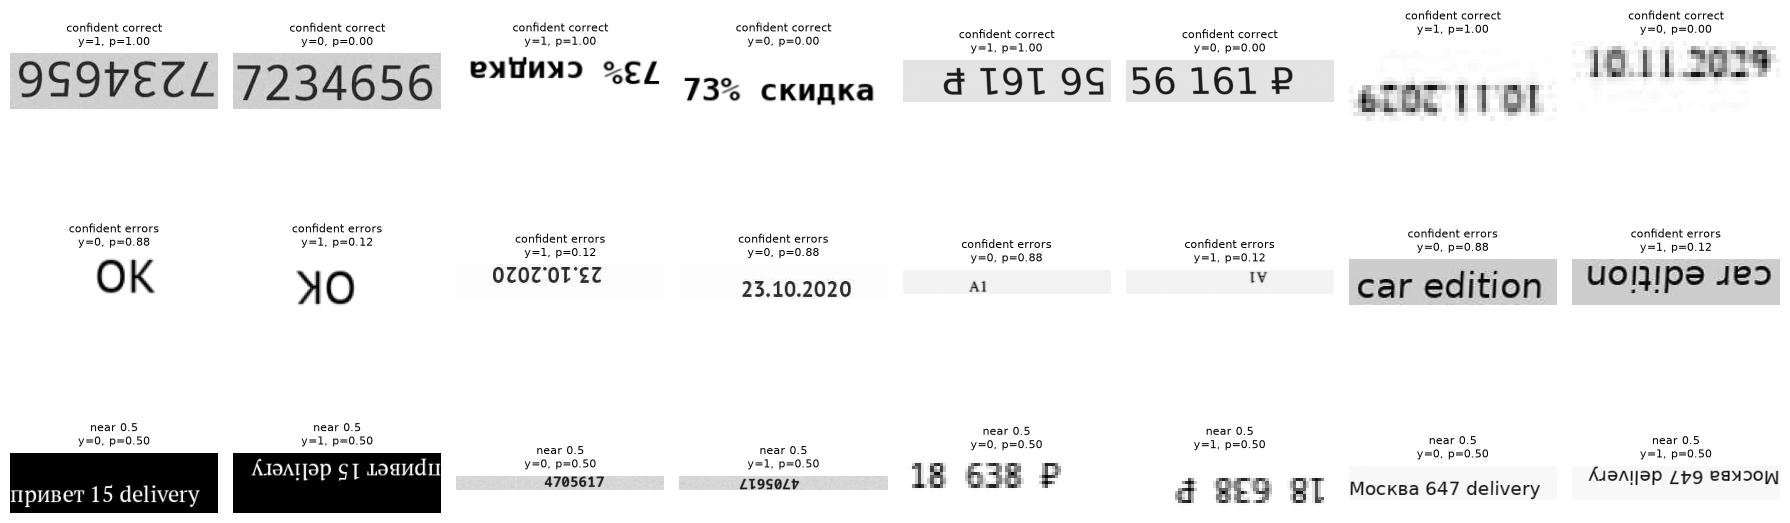

,n,accuracy
type,,
contains digits,2716,0.678203
other,1130,0.547788
very short,154,0.655844


In [25]:
correct=(final_val_p>=.5)==y_val
confidence=np.abs(final_val_p-.5)
sets={'confident correct':np.where(correct)[0][np.argsort(-confidence[correct])[:8]],
      'confident errors':np.where(~correct)[0][np.argsort(-confidence[~correct])[:8]],
      'near 0.5':np.argsort(confidence)[:8]}
fig,axs=plt.subplots(3,8,figsize=(18,7))
for row,(title,indices) in enumerate(sets.items()):
    for col,ax in enumerate(axs[row]):
        if col<len(indices):
            k=indices[col]; ax.imshow(get_synthetic(va_ids[k],y_val[k]),cmap='gray')
            ax.set_title(f'{title}\ny={y_val[k]}, p={final_val_p[k]:.2f}',fontsize=8)
        ax.axis('off')
plt.tight_layout(); plt.show()
analysis=pd.DataFrame({'group_id':manifest.iloc[va_ids].group_id.to_numpy(),
                       'text':manifest.iloc[va_ids].text.to_numpy(),
                       'font':manifest.iloc[va_ids].font.to_numpy(),
                       'y':y_val,'p':final_val_p,'correct':correct})
analysis['type']=np.select([analysis.text.str.contains(r'\d',regex=True),
                            analysis.text.str.len().le(4)],['contains digits','very short'],default='other')
display(analysis.groupby('type').agg(n=('correct','size'),accuracy=('correct','mean')))
analysis.to_csv(ARTIFACT_DIR/'validation_errors.csv',index=False)

Короткие строки, цифры и размытый мелкий текст часто дают мало информации об ориентации.

## 12. Скорость и результаты baseline

In [26]:
                                                                                   
bench_ids,bench_y=va_ids[:min(200,len(va_ids))],y_val[:min(200,len(y_val))]
bench=[]
for name,model,fn,_ in candidate_models:
    t0=time.perf_counter()
    xb=np.stack([fn(get_synthetic(i,y)) for i,y in zip(bench_ids,bench_y)])
    prep=time.perf_counter()-t0
    t0=time.perf_counter(); _=model.predict_proba(xb)[:,1]; pred=time.perf_counter()-t0
    bench.append(dict(model=name,feature_dim=xb.shape[1],preprocessing_ms=1000*prep/len(xb),
                      model_predict_ms=1000*pred/len(xb),inference_ms=1000*(prep+pred)/len(xb),
                      images_sec=len(xb)/(prep+pred),model_size_mb=len(pickle.dumps(model))/1024**2))
bench_df=pd.DataFrame(bench).sort_values('inference_ms')
display(bench_df)
experiment_table=pd.DataFrame(results)
experiment_table=experiment_table.sort_values('score',ascending=False)
display(experiment_table[['model','features','score','brier','accuracy','auc','inference_ms','model_size_mb']])
experiment_table.to_csv(ARTIFACT_DIR/'experiments.csv',index=False)
print('Выбрана модель:',best_name,'| symmetry:',use_sym,'| validation score:',1-brier_score_loss(y_val,final_val_p))

,model,feature_dim,preprocessing_ms,model_predict_ms,inference_ms,images_sec,model_size_mb
0,handcrafted LR,18,0.752048,0.002414,0.754462,1325.447530,0.001543
1,HOG LR,1080,1.006383,0.003346,1.009729,990.364325,0.029919
4,HOG LR isotonic,1080,1.003269,0.007152,1.010420,989.687001,0.030793
2,HOG SVM sigmoid,1080,1.003967,0.007159,1.011126,988.996568,0.034288
3,HOG LR sigmoid,1080,1.024397,0.006481,1.030878,970.047170,0.030333


,model,features,score,brier,accuracy,auc,inference_ms,model_size_mb
7,HOG LR isotonic,1080,0.783449,0.216551,0.64050,0.703326,0.955556,0.030793
6,HOG LR sigmoid,1080,0.782667,0.217333,0.63975,0.705188,0.955742,0.030333
5,HOG SVM sigmoid,1080,0.782646,0.217354,0.64150,0.705619,0.965432,0.034288
3,HOG 8x8 / 6 LR,1080,0.778107,0.221893,0.63975,0.705188,0.965867,0.029919
4,HOG 12x8 / 9 LR,972,0.777871,0.222129,0.64075,0.702837,0.835181,0.027035
2,HOG 8x8 / 9 LR,1620,0.773529,0.226471,0.64250,0.710295,1.005859,0.044338
1,handcrafted LR,18,0.754473,0.245527,0.56250,0.580173,0.711110,0.001543
0,constant 0.5,0,0.750000,0.250000,0.50000,0.500000,0.000012,0.000000


Выбрана модель: HOG LR isotonic | symmetry: True | validation score: 0.7834489517641947


Главный критерий здесь `1-Brier`. Время включает подготовку изображения и предсказание.

## 13. Идея из статьи

[Joost van Beusekom, Faisal Shafait, Thomas M. Breuel. *Resolution Independent Skew and Orientation Detection for Document Images*. SPIE, 2009](https://www.dfki.de/fileadmin/user_upload/import/4331_beusekom--resolution-independent-skew-and-orientation-detection-for-document-images--SPIE--2009.pdf). [DOI 10.1117/12.807735](https://doi.org/10.1117/12.807735).

Берём идею сравнения выравнивания нижних и верхних границ букв.

### Что еще рассматривали
| Источник | Год | Идея | Почему не выбрали |
|---|---|---|---|
| [Lu, Wang, Tan](https://doi.org/10.1109/ICDAR.2007.4377002) | 2007 | Белые пробеги между строками | В боксе обычно одна строка |
| [Aradhye](https://doi.org/10.1016/j.patcog.2004.12.011) | 2005 | Направление открытых частей букв | Нужна более сложная сегментация |
| [Vijayashree и соавторы](https://doi.org/10.11591/ijece.v6i5.10785) | 2016 | Статистика направленных градиентов | Меньше связи с геометрией текста |

Первый источник подходит короткой строке после упрощения поиска линии. Метод остаётся быстрым и компактным.

## 14. Почему признак должен работать

**Baseline** задаёт нижнюю линию большинства букв. **Ascenders** поднимаются выше обычных строчных букв. **Descenders** опускаются ниже baseline. Нижние границы букв часто лучше выровнены, чем верхние. После поворота на 180° верх и низ меняются местами.

Короткая строка и цифры могут нарушать это правило. Поэтому качество нужно измерить, а не принимать на веру.

## 15. Как реализовываем

### Что делают авторы

Они подбирают две параллельные линии для нижних границ связных компонент. Одна соответствует baseline, другая descenders. Для верхних границ строят похожую модель x-height и ascenders. На странице ищут несколько строк алгоритмом RAST и сравнивают качество разных ориентаций.

$$Q(r,d)=\sum_i\max\{q_r(x_i),\alpha q_{r+d}(x_i)\},\qquad \alpha=0.75.$$

### Что делаем мы

У нас один текстовый бокс. Мы перебираем возможные строки после уменьшения изображения до 128×32 и не оцениваем skew. Расстояния задаём относительно высоты компонент.

- `A` оценивает одну линию
- `B` оценивает две линии по идее статьи
- `C` измеряет вертикальный центр штрихов, это наше дополнение

Позже проверим вес признаков и калибровку. Эти изменения не приписываем авторам.

## 16. Те же данные для нового опыта

In [27]:
from pathlib import Path
import pickle, time
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("module://matplotlib_inline.backend_inline", force=True)
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image
from scipy import ndimage as ndi
from scipy.optimize import minimize_scalar
from scipy.special import expit
from skimage.filters import threshold_otsu
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, roc_auc_score, brier_score_loss
from sklearn.model_selection import GroupShuffleSplit
from sklearn.calibration import calibration_curve
from IPython.display import display, Markdown

ROOT=Path.cwd(); ART=ROOT/'artifacts'; SEED=RANDOM_SEED
manifest_path=ART/f'synthetic_manifest_{N_BASE_SAMPLES}_{RANDOM_SEED}_{FONT_SET_VERSION}.csv'
assert manifest_path.exists(), 'Сначала выполните ячейки генерации синтетики.'
manifest=pd.read_csv(manifest_path)
assert len(manifest)==N_BASE_SAMPLES and manifest.group_id.is_unique
assert all(Path(p).exists() for p in manifest.path)
sample=pd.read_csv(ROOT/'sample_submission.csv',dtype={'image_id':str})
test_dir=ROOT/'test/images'
assert len(sample)==20000 and test_dir.exists()
traincal,val=next(GroupShuffleSplit(n_splits=1,test_size=.2,random_state=SEED).split(manifest,groups=manifest.group_id))
tr,ca=next(GroupShuffleSplit(n_splits=1,test_size=.2,random_state=SEED+1).split(traincal,groups=manifest.iloc[traincal].group_id))
train,cal=traincal[tr],traincal[ca]
assert not set(train)&set(cal) and not set(train)&set(val) and not set(cal)&set(val)
print('Base instances: train',len(train),'calibration',len(cal),'validation',len(val))

Base instances: train 6400 calibration 1600 validation 2000


Повторяем тот же group split. Сравнение с baseline относится к тем же изображениям.

## 17. Геометрия компонент

In [28]:
W,H=128,32

def foreground_components(image, details=False):
    a=np.asarray(image.convert('L').resize((W,H),Image.Resampling.BILINEAR),dtype=np.float32)
    border=np.r_[a[0],a[-1],a[:,0],a[:,-1]]
    contrast=np.abs(a-np.median(border))
    threshold=max(10.,float(threshold_otsu(contrast))) if np.ptp(contrast)>1 else 10.
    mask=contrast>threshold
    labels,_=ndi.label(mask,np.ones((3,3),dtype=np.uint8))
    components=[]
    for sl in ndi.find_objects(labels):
        if sl is None: continue
        sy,sx=sl; h=sy.stop-sy.start; w=sx.stop-sx.start
        area=int(mask[sy,sx].sum())
        if 3<=h<=H*.85 and 2<=w<=W*.5 and 5<=area<=W*H*.35:
            components.append((sx.start,sy.start,sx.stop,sy.stop))
    return (mask,components) if details else components

def line_qualities(points, second_direction, d, eps):
    rows=np.arange(H,dtype=np.float32)[:,None]
    positions=np.asarray(points,dtype=np.float32)[None,:]
    q0=np.maximum(0,1-((positions-rows)/eps)**2)
    q1=np.maximum(0,1-((positions-(rows+second_direction*d))/eps)**2)
    single=q0.sum(axis=1)
    double=np.maximum(q0,.75*q1).sum(axis=1)
    return float(single.max()),float(double.max()),int(double.argmax())

def orientation_features(image, details=False):
    mask,cc=foreground_components(image,True)
    n=len(cc)
    if n<2:
        f=np.zeros(6,dtype=np.float32)
        return (f,{'mask':mask,'cc':cc,'n':n}) if details else f
    top=np.array([y0 for x0,y0,x1,y1 in cc]); bottom=np.array([y1-1 for x0,y0,x1,y1 in cc])
    heights=np.array([y1-y0 for x0,y0,x1,y1 in cc])
    median_h=float(np.median(heights)); d=max(1.5,.23*median_h); eps=max(1.25,.13*median_h)
    bs,bd,baseline=line_qualities(bottom,+1,d,eps)
    ts,td,xline=line_qualities(top,-1,d,eps)
    A=(bs-ts)/n; B=(bd-td)/n
    profile=mask.sum(axis=1).astype(np.float32)
    active=np.flatnonzero(profile)
    mid=(active[0]+active[-1])/2 if len(active) else (H-1)/2
    span=max(1,int(active[-1]-active[0])) if len(active) else H-1
    C=float(np.dot(profile,np.arange(H)-mid)/(max(1,profile.sum())*span))
    reliability=n/(n+5)
    f=np.array([A,B,C,A*reliability,B*reliability,C*reliability],dtype=np.float32)
    info={'mask':mask,'cc':cc,'n':n,'baseline':baseline,'xline':xline,'profile':profile,'A':A,'B':B,'C':C,'d':d,'eps':eps}
    return (f,info) if details else f

with Image.open(manifest.iloc[0].path) as im:
    f0,info0=orientation_features(im,True)
    fr=orientation_features(im.transpose(Image.Transpose.ROTATE_180))
print('features:',f0,'rotated:',fr,'symmetry error:',np.max(np.abs(f0+fr)))

features: [0.         0.         0.01037202 0.         0.         0.00296343] rotated: [ 0.          0.         -0.01037202  0.          0.         -0.00296343] symmetry error: 0.0


`A` и `B` сравнивают нижнюю и верхнюю стороны компонент. `C` проверяет, где сосредоточены штрихи. Поворот должен менять знак этих признаков.

## 18. Посмотрим, что видит метод

Explanatory synthetic examples selected by positive B; unbiased evaluation uses all validation images.


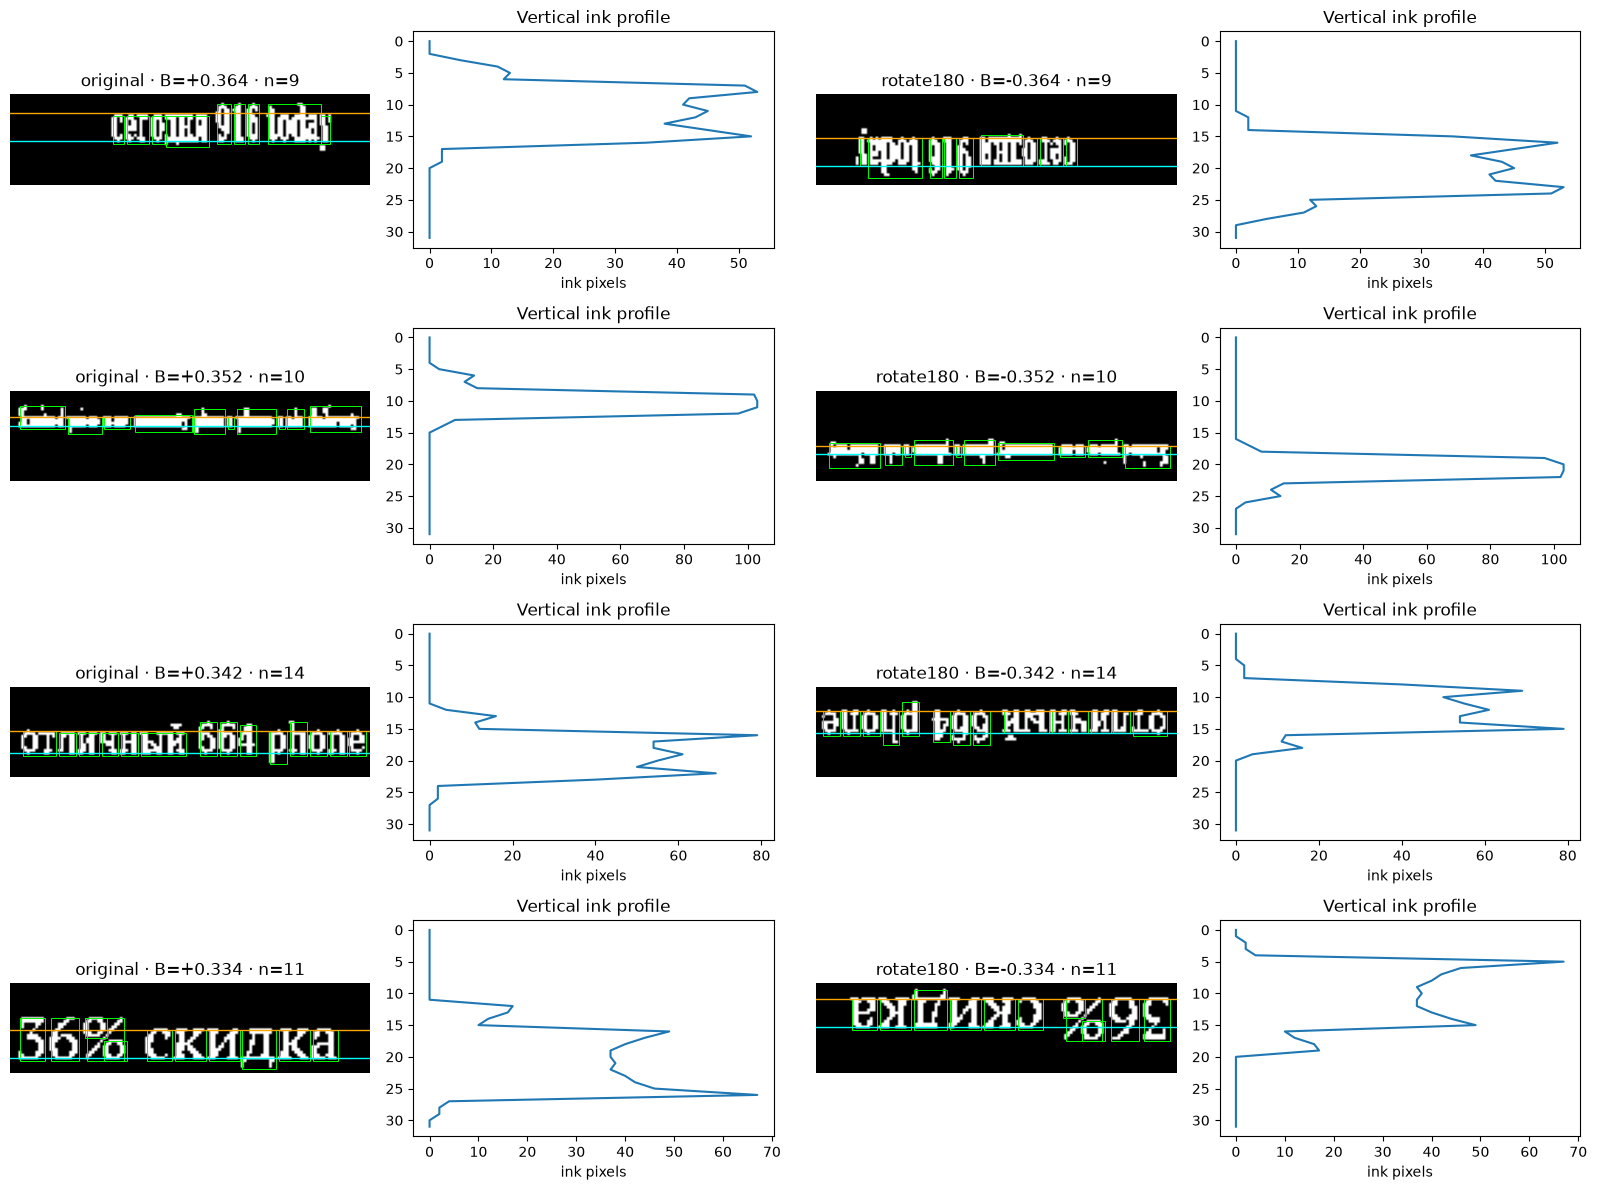

Rotation feature symmetry: mean/max: 3.0075576e-08 2.3841858e-07
S(x), S(Rx), D(x), D(Rx): 0.36446226 -0.36446217 0.7289244 -0.7289244


In [29]:
visual_candidates=[]
for idx in val[:200]:
    with Image.open(manifest.iloc[int(idx)].path) as im:
        f,info=orientation_features(im,True)
    if info['n']>=4: visual_candidates.append((float(f[1]),int(idx)))
examples=[idx for score,idx in sorted(visual_candidates,reverse=True)[:4]]
print('Explanatory synthetic examples selected by positive B; unbiased evaluation uses all validation images.')
fig,axs=plt.subplots(4,4,figsize=(16,12))
for row,idx in enumerate(examples):
    with Image.open(manifest.iloc[idx].path) as original: base=original.copy()
    for side,im in enumerate([base,base.transpose(Image.Transpose.ROTATE_180)]):
        f,info=orientation_features(im,True)
        image_ax=axs[row,2*side]; profile_ax=axs[row,2*side+1]
        image_ax.imshow(info['mask'],cmap='gray',vmin=0,vmax=1)
        for x0,y0,x1,y1 in info['cc']:
            image_ax.add_patch(Rectangle((x0,y0),x1-x0,y1-y0,fill=False,edgecolor='lime',linewidth=.7))
        if info['n']>=2:
            image_ax.axhline(info['baseline'],color='cyan',lw=1)
            image_ax.axhline(info['xline'],color='orange',lw=1)
        image_ax.set_title(f"{'original' if side==0 else 'rotate180'} · B={f[1]:+.3f} · n={info['n']}")
        image_ax.axis('off')
        profile_ax.plot(info.get('profile',info['mask'].sum(axis=1)),np.arange(H))
        profile_ax.invert_yaxis(); profile_ax.set_title('Vertical ink profile'); profile_ax.set_xlabel('ink pixels')
plt.tight_layout(); plt.show()

errors=[]
for idx in val[:min(200,len(val))]:
    with Image.open(manifest.iloc[idx].path) as im:
        a=orientation_features(im); b=orientation_features(im.transpose(Image.Transpose.ROTATE_180))
    errors.append(np.max(np.abs(a+b)))
print('Rotation feature symmetry: mean/max:',np.mean(errors),np.max(errors))
with Image.open(manifest.iloc[examples[0]].path) as im:
    s=orientation_features(im)[1]
    sr=orientation_features(im.transpose(Image.Transpose.ROTATE_180))[1]
D=s-sr; Dr=sr-s
print('S(x), S(Rx), D(x), D(Rx):',s,sr,D,Dr)
assert np.isclose(D,-Dr)

Зелёные прямоугольники показывают компоненты, голубая и оранжевая линии показывают найденные уровни. Для наглядности примеры выбраны среди строк с сильным геометрическим сигналом. Оценка ниже использует всю validation.

## 19. Признаки и пары

In [30]:
cache=ART/f'article_features_{N_BASE_SAMPLES}_{RANDOM_SEED}_{FONT_SET_VERSION}.npz'
if cache.exists():
    base_features=np.load(cache)['features']
else:
    start=time.perf_counter(); vectors=[]
    for j,path in enumerate(manifest.path):
        with Image.open(path) as im: vectors.append(orientation_features(im))
        if (j+1)%2500==0: print('Extracted',j+1,'of',len(manifest))
    base_features=np.stack(vectors)
    np.savez_compressed(cache,features=base_features)
    print('Feature extraction seconds:',round(time.perf_counter()-start,2))
assert base_features.shape==(N_BASE_SAMPLES,6)
print('Upright feature means:',np.round(base_features[:,:3].mean(axis=0),4))
print('Nonzero fraction:',np.mean(np.any(base_features!=0,axis=1)))

Upright feature means: [0.0654 0.0483 0.0015]
Nonzero fraction: 0.9707


Сначала делим исходные строки, затем используем $f(x)$ и $-f(x)$ как повёрнутую пару. Прямой поворот выше проверяет это равенство.

In [31]:
def paired_features(indices):
    X=np.concatenate([base_features[indices],-base_features[indices]])
    y=np.r_[np.zeros(len(indices),dtype=int),np.ones(len(indices),dtype=int)]
    return X,y
Xtr,ytr=paired_features(train); Xca,yca=paired_features(cal); Xva,yva=paired_features(val)
assert np.array_equal(np.unique(yva,return_counts=True)[1],[len(val),len(val)])

## 20. Что даёт каждая часть метода

In [32]:
feature_sets={
    'A: single line':(0,),
    'B: two-line geometry':(1,),
    'A+B':(0,1),
    'A+B+C':(0,1,2),
    'full: + count reliability':(0,1,2,3,4,5),
}

def fit_and_calibrate(columns):
    model=LogisticRegression(fit_intercept=False,max_iter=1000,C=1,random_state=SEED)
    start=time.perf_counter(); model.fit(Xtr[:,columns],ytr); fit_s=time.perf_counter()-start
    cal_logit=model.decision_function(Xca[:,columns])
    objective=lambda log_t:brier_score_loss(yca,expit(cal_logit/np.exp(log_t)))
    start=time.perf_counter(); optimum=minimize_scalar(objective,bounds=(-3,4),method='bounded')
    cal_s=time.perf_counter()-start
    T=float(np.exp(optimum.x))
    logits=model.decision_function(Xva[:,columns])
    return model,T,fit_s+cal_s,expit(logits/T)

runs={}
for name,cols in feature_sets.items():
    model,T,fit_s,p=fit_and_calibrate(cols)
    runs[name]=dict(model=model,T=T,cols=cols,p=p,fit_s=fit_s)
    print(name,'T=',round(T,3),'coef=',np.round(model.coef_,3))

def metric_row(name,p,y=yva):
    return dict(model=name,accuracy=accuracy_score(y,p>=.5),auc=roc_auc_score(y,p),
                brier=brier_score_loss(y,p),score=1-brier_score_loss(y,p))
ablation=pd.DataFrame([dict(features=name,**metric_row(name,run['p'])) for name,run in runs.items()])
display(ablation[['features','accuracy','auc','brier','score']].sort_values('score',ascending=False))
ablation.to_csv(ART/'article_ablation.csv',index=False)

A: single line T= 0.915 coef= [[-4.342]]
B: two-line geometry T= 0.92 coef= [[-6.377]]
A+B T= 0.916 coef= [[-1.815 -4.265]]
A+B+C T= 0.842 coef= [[-2.576 -4.429  5.813]]
full: + count reliability T= 0.875 coef= [[ 0.98  -0.842  1.711 -6.153 -6.161  7.901]]


,features,accuracy,auc,brier,score
4,full: + count reliability,0.66600,0.738329,0.206562,0.793438
3,A+B+C,0.66400,0.731572,0.209721,0.790279
2,A+B,0.63025,0.702237,0.217296,0.782704
1,B: two-line geometry,0.63575,0.703672,0.217856,0.782144
0,A: single line,0.62225,0.688854,0.221776,0.778224


`B` ближе всего к идее статьи. `A`, `C` и учёт числа компонент добавлены нами. Веса учим на train, температуру на calibration, результат считаем на validation.

## 21. Вероятности и симметрия

Uncalibrated Brier: 0.2064971625804901 calibrated: 0.20656180381774902
Pairwise p(x)+p(Rx)-1 max: 1.1920929e-07


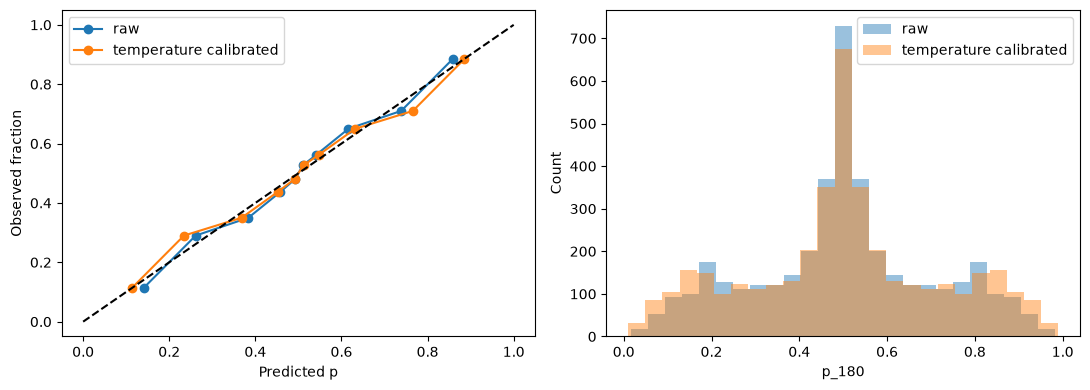

In [33]:
selected='full: + count reliability'
run=runs[selected]; cols=run['cols']; z=run['model'].decision_function(Xva[:,cols])
raw=expit(z); calibrated=run['p']
print('Uncalibrated Brier:',brier_score_loss(yva,raw),'calibrated:',brier_score_loss(yva,calibrated))
print('Pairwise p(x)+p(Rx)-1 max:',np.max(np.abs(calibrated[:len(val)]+calibrated[len(val):]-1)))
fig,axs=plt.subplots(1,2,figsize=(11,4))
for name,p in [('raw',raw),('temperature calibrated',calibrated)]:
    frac,mean=calibration_curve(yva,p,n_bins=10,strategy='quantile')
    axs[0].plot(mean,frac,'o-',label=name)
    axs[1].hist(p,bins=25,alpha=.45,label=name)
axs[0].plot([0,1],[0,1],'k--');axs[0].set(xlabel='Predicted p',ylabel='Observed fraction')
axs[1].set(xlabel='p_180',ylabel='Count')
for ax in axs: ax.legend()
plt.tight_layout();plt.show()

Нулевой intercept и парные признаки дают $p(R_{180}x)\approx1-p(x)$. Температура меняет уверенность, но сохраняет симметрию.

## 22. Сравнение скорости и качества

In [34]:
benchmark_idx=val[:500]
start=time.perf_counter(); bench=[]
for idx in benchmark_idx:
    with Image.open(manifest.iloc[idx].path) as im: bench.append(orientation_features(im))
extract_s=time.perf_counter()-start
bench=np.stack(bench)
start=time.perf_counter(); _=expit(run['model'].decision_function(bench[:,cols])/run['T'])
predict_s=time.perf_counter()-start
new_ms=1000*(extract_s+predict_s)/len(bench)
new_row=metric_row('article: geometry full',calibrated)
new_row.update(features=len(cols),inference_ms=new_ms,images_sec=1000/new_ms,
               model_size_mb=len(pickle.dumps((run['model'],run['T'],cols)))/1024**2,
               training_s=run['fit_s'])
old=pd.read_csv(ART/'experiments.csv')
old=old[old.model.isin(['constant 0.5','handcrafted LR','HOG 12x8 / 9 LR','HOG LR sigmoid'])]
old=old[['model','features','accuracy','auc','brier','score','inference_ms','images_sec','model_size_mb','training_s']]
comparison=pd.concat([old,pd.DataFrame([new_row])],ignore_index=True).sort_values('score',ascending=False)
display(comparison)
comparison.to_csv(ART/'article_experiments.csv',index=False)
all_results=pd.read_csv(ART/'experiments.csv')
all_results=all_results[all_results.model!='article: geometry full']
all_results=pd.concat([all_results,pd.DataFrame([new_row])],ignore_index=True)
all_results.to_csv(ART/'experiments.csv',index=False)
print('Geometry feature extraction ms/image:',1000*extract_s/len(bench),
      'probability calculation ms/image:',1000*predict_s/len(bench))

,model,features,accuracy,auc,brier,score,inference_ms,images_sec,model_size_mb,training_s
4,article: geometry full,6,0.66600,0.738329,0.206562,0.793438,0.707000,1.414428e+03,0.000710,0.017812
0,HOG LR sigmoid,1080,0.63975,0.705188,0.217333,0.782667,0.955742,1.046308e+03,0.030333,0.067287
1,HOG 12x8 / 9 LR,972,0.64075,0.702837,0.222129,0.777871,0.835181,1.197346e+03,0.027035,7.091617
2,handcrafted LR,18,0.56250,0.580173,0.245527,0.754473,0.711110,1.406251e+03,0.001543,0.011662
3,constant 0.5,0,0.50000,0.500000,0.250000,0.750000,0.000012,8.458448e+07,0.000000,0.000000


Geometry feature extraction ms/image: 0.7063025120005477 probability calculation ms/image: 0.0006971920010983013


Строка нового метода попадает в общую таблицу `artifacts/experiments.csv`. Время измерено приблизительно на той же машине.

## 23. Когда геометрия ошибается

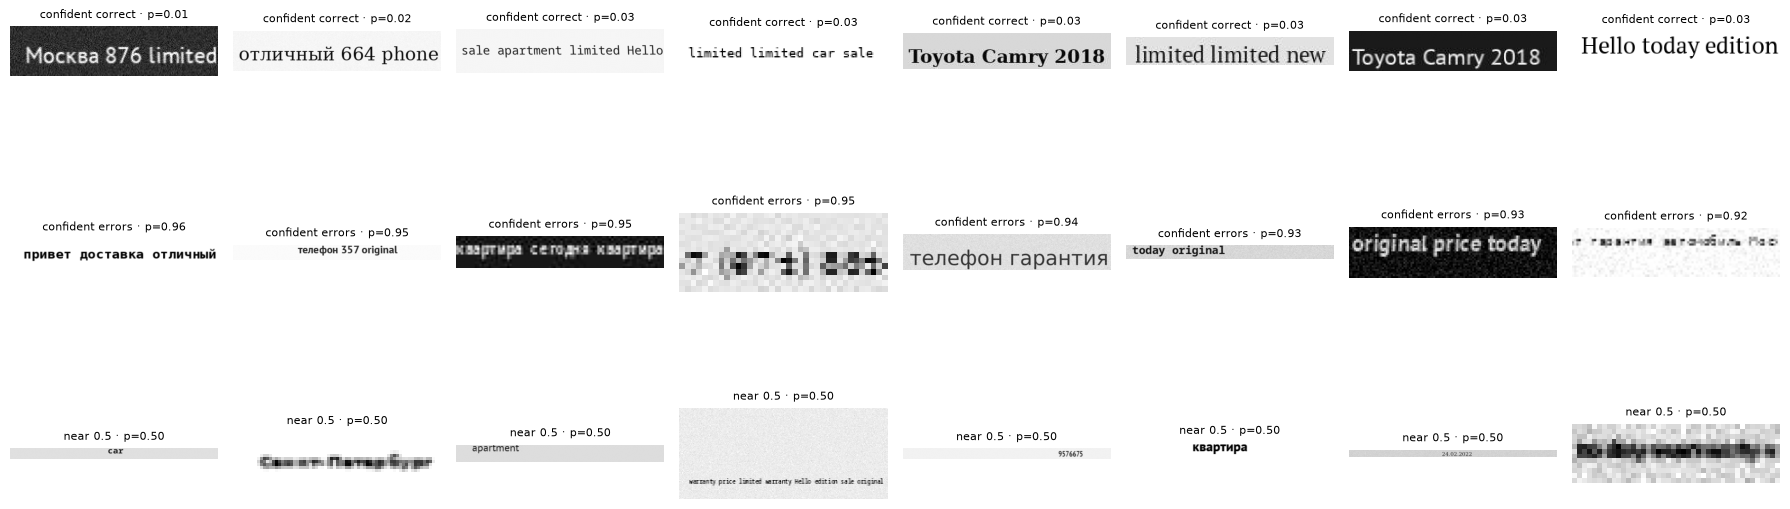

,n,accuracy
few_components,,
False,1688,0.701422
True,312,0.368590


,n,accuracy
contains_digit,,
False,642,0.535826
True,1358,0.703240


,n,accuracy
short,,
False,1837,0.675014
True,163,0.361963


In [35]:
p0=calibrated[:len(val)]; correct=p0<.5; conf=np.abs(p0-.5)
sets={'confident correct':np.where(correct)[0][np.argsort(-conf[correct])[:8]],
      'confident errors':np.where(~correct)[0][np.argsort(-conf[~correct])[:8]],
      'near 0.5':np.argsort(conf)[:8]}
fig,axs=plt.subplots(3,8,figsize=(18,7))
for row,(title,indices) in enumerate(sets.items()):
    for col,ax in enumerate(axs[row]):
        if col<len(indices):
            j=int(indices[col]); idx=int(val[j])
            with Image.open(manifest.iloc[idx].path) as im: ax.imshow(im,cmap='gray')
            ax.set_title(f'{title} · p={p0[j]:.2f}',fontsize=8)
        ax.axis('off')
plt.tight_layout();plt.show()
err=pd.DataFrame({'text':manifest.iloc[val].text.to_numpy(),
                  'height':manifest.iloc[val].height.to_numpy(),
                  'n_components':np.array([len(foreground_components(Image.open(manifest.iloc[int(i)].path))) for i in val]),
                  'p_180':p0,'correct':correct})
err['contains_digit']=err.text.str.contains(r'\d',regex=True)
err['short']=err.text.str.len()<5
err['few_components']=err.n_components<4
display(err.groupby('few_components').agg(n=('correct','size'),accuracy=('correct','mean')))
display(err.groupby('contains_digit').agg(n=('correct','size'),accuracy=('correct','mean')))
display(err.groupby('short').agg(n=('correct','size'),accuracy=('correct','mean')))
err.to_csv(ART/'article_validation_errors.csv',index=False)

## 24. Разница между синтетикой и test

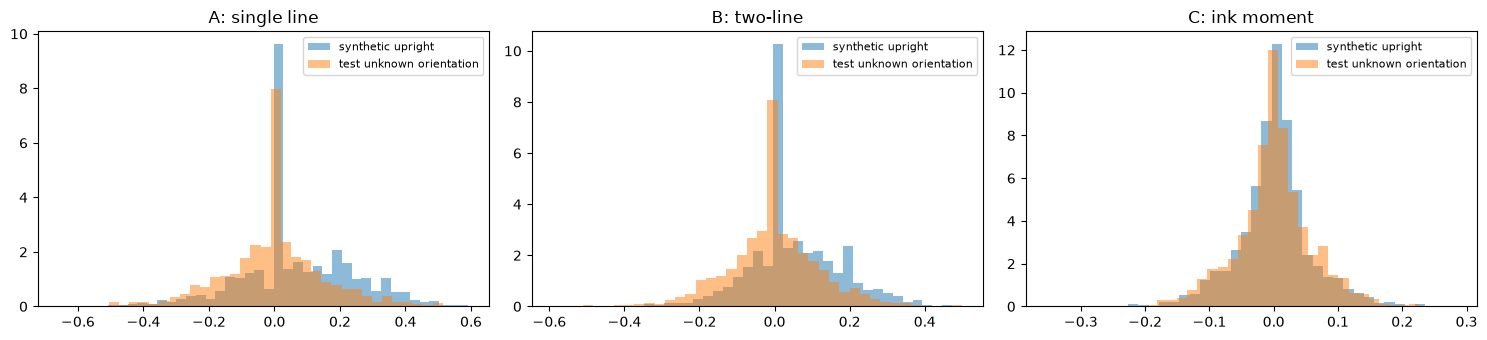

Synthetic mean/std: [0.0638391  0.04837279 0.00097873] [0.17182875 0.12404823 0.05767542]
Test mean/std: [-0.00186592 -0.00275573  0.00103418] [0.15482093 0.12245521 0.06002339]
Zero-feature fraction synthetic/test: 0.0355 0.063


In [36]:
rng=np.random.default_rng(SEED)
ids=rng.choice(len(sample),size=2000,replace=False)
test_features=[]
for i in ids:
    path=test_dir/f"{sample.iloc[int(i)].image_id}.png"
    with Image.open(path) as im: test_features.append(orientation_features(im))
test_features=np.stack(test_features)
synthetic_probe=base_features[rng.choice(len(base_features),size=2000,replace=False)]
fig,axs=plt.subplots(1,3,figsize=(15,3.5))
for ax,k,title in zip(axs,range(3),['A: single line','B: two-line','C: ink moment']):
    ax.hist(synthetic_probe[:,k],bins=40,density=True,alpha=.5,label='synthetic upright')
    ax.hist(test_features[:,k],bins=40,density=True,alpha=.5,label='test unknown orientation')
    ax.set_title(title);ax.legend(fontsize=8)
plt.tight_layout();plt.show()
print('Synthetic mean/std:',synthetic_probe[:,:3].mean(axis=0),synthetic_probe[:,:3].std(axis=0))
print('Test mean/std:',test_features[:,:3].mean(axis=0),test_features[:,:3].std(axis=0))
print('Zero-feature fraction synthetic/test:',np.mean(np.all(synthetic_probe==0,axis=1)),np.mean(np.all(test_features==0,axis=1)))

Гистограмма test смешивает обе неизвестные ориентации. Она не измеряет качество. Она помогает увидеть, насколько признаки изменились на реальных боксах.

## 25. Идея статьи и наше дополнение

In [37]:
original=ablation.set_index('features').loc['B: two-line geometry']
improved=ablation.set_index('features').loc['full: + count reliability']
display(pd.DataFrame([original,improved],index=['Original adaptation (B)','Our improved version (full)'])[['accuracy','auc','brier','score']])

,accuracy,auc,brier,score
Original adaptation (B),0.63575,0.703672,0.217856,0.782144
Our improved version (full),0.66600,0.738329,0.206562,0.793438


Сравниваем двухлинейную геометрию `B` и полный набор. Если дополнения не помогают, это видно по Brier.

## 26. Выводы

In [38]:
hog=comparison.loc[comparison.model=='HOG LR sigmoid'].iloc[0]
article=comparison.loc[comparison.model=='article: geometry full'].iloc[0]
verdict=('как самостоятельный быстрый сигнал' if article.score>=hog.score else
         'скорее как дополнительный сигнал для будущей модели')
summary=f"""### 1. Из статьи
Сравнение верхних и нижних границ компонент с двумя параллельными линиями.

### 2. Наши изменения
Один бокс вместо страницы. Перебор строк без RAST. Нормировка, признаки A и C, парная симметрия и калибровка.

### 3. Почему работает
Общая baseline выравнивает нижние границы букв. Поворот меняет верх и низ местами.

### 4. Качество
Наш метод получил score {article.score:.4f} и Brier {article.brier:.4f}. HOG получил score {hog.score:.4f} и Brier {hog.brier:.4f}. Разница score {article.score-hog.score:+.4f}.

### 5. Скорость
{article.inference_ms:.3f} мс на изображение. {article.images_sec:.0f} изображений в секунду. Размер модели {article.model_size_mb:.4f} МБ.

### 6. Слабые места
Короткие строки, цифры, прописные и симметричные буквы, blur, crop и мало отдельных компонент.

### 7. Что дальше
Метод подходит {verdict}. Качество на test без меток неизвестно. Позже можно добавить этот score к вероятности CNN.
"""
display(Markdown(summary))

### 1. Из статьи
Сравнение верхних и нижних границ компонент с двумя параллельными линиями.

### 2. Наши изменения
Один бокс вместо страницы. Перебор строк без RAST. Нормировка, признаки A и C, парная симметрия и калибровка.

### 3. Почему работает
Общая baseline выравнивает нижние границы букв. Поворот меняет верх и низ местами.

### 4. Качество
Наш метод получил score 0.7934 и Brier 0.2066. HOG получил score 0.7827 и Brier 0.2173. Разница score +0.0108.

### 5. Скорость
0.707 мс на изображение. 1414 изображений в секунду. Размер модели 0.0007 МБ.

### 6. Слабые места
Короткие строки, цифры, прописные и симметричные буквы, blur, crop и мало отдельных компонент.

### 7. Что дальше
Метод подходит как самостоятельный быстрый сигнал. Качество на test без меток неизвестно. Позже можно добавить этот score к вероятности CNN.


## 27. Submission нового метода

Этот файл отражает лучший вариант в исследовании. Test не использовался для настройки весов или меток.

In [39]:
test_probs=[]
for start in range(0,len(sample),256):
    paths=[test_dir/f'{image_id}.png' for image_id in sample.image_id.iloc[start:start+256]]
    vectors=[]
    for path in paths:
        with Image.open(path) as im:
            vectors.append(orientation_features(im))
    x=np.stack(vectors)
    test_probs.extend(expit(run['model'].decision_function(x[:,cols])/run['T']))
submission_article=pd.DataFrame({'image_id':sample.image_id,'p_180':np.asarray(test_probs)})
assert len(submission_article)==20000
assert submission_article.image_id.equals(sample.image_id)
assert submission_article.p_180.notna().all()
assert submission_article.p_180.between(0,1).all()
submission_article.to_csv(ROOT/'submission_article.csv',index=False)
display(submission_article.head())
print('Saved submission.csv')

,image_id,p_180
0,test_00000,0.500000
1,test_00001,0.378306
2,test_00002,0.509685
3,test_00003,0.370835
4,test_00004,0.666640


Saved submission.csv


Готов `submission.csv` с вероятностями нового метода.